# 01_eda: Exploración y preparación de UNSW-NB15
**Persona A.** Regla de oro: el conjunto de **prueba no se usa para decidir nada**. Todas las estadísticas que guían decisiones (asimetría, categorías, submuestra) se calculan solo con entrenamiento.

## 0. Configuración y reproducibilidad

In [1]:
import sys, os, platform, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn
warnings.filterwarnings("ignore")

# --- AJUSTA ESTAS RUTAS A DONDE SUBISTE LOS CSV ---
# En esta copia local los nombres de los CSV están invertidos: train tiene 175341 filas y test 82332.
RUTA_TRAIN = "../data/UNSW_NB15_testing-set.csv"
RUTA_TEST  = "../data/UNSW_NB15_training-set.csv"
RUTA_SRC   = "../src"          # carpeta donde está preprocesamiento.py (en Colab: "." si lo subes junto al notebook)

sys.path.insert(0, RUTA_SRC)
import preprocesamiento as pp

SEED = pp.SEED   # 42
np.random.seed(SEED)

print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
print("Sistema:", platform.platform(), "| Procesador:", platform.processor())
print(sys.executable)

Python 3.13.0 | pandas 3.1.0 | numpy 2.5.4 | scikit-learn 1.9.1
Sistema: Windows-11-10.0.26200-SP0 | Procesador: AMD64 Family 23 Model 96 Stepping 1, AuthenticAMD
c:\Users\casa\proyecto_parcial_integrador\proyecto-ic\.venv\Scripts\python.exe


In [2]:
# Hardware (para la sección de reproducibilidad del informe)
print("Núcleos CPU:", os.cpu_count())
try:
    import psutil; print("RAM (GB):", round(psutil.virtual_memory().total/1e9, 1))
except ImportError:
    print("RAM: instala psutil o anótala a mano")

Núcleos CPU: 4
RAM (GB): 7.9


## 1. Carga de datos (partición oficial)

In [3]:
train, test = pp.cargar_datos(RUTA_TRAIN, RUTA_TEST)
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (175341, 45) | test: (82332, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


ELIMINAR DUPLICADOS

In [4]:
# ==========================================
# AUDITORÍA Y LIMPIEZA DE DUPLICADOS
# ==========================================

# Conservar una copia de los datos originales
train_original = train.copy()

# Columnas predictoras, excluyendo identificador,
# categoría detallada de ataque y etiqueta objetivo
feat = [
    c for c in train.columns
    if c not in ("id", "attack_cat", "label")
]

print("REGISTROS ORIGINALES:", len(train))

# 1. Identificar combinaciones de características
# asociadas a más de una etiqueta binaria
etiquetas_por_registro = train.groupby(
    feat, dropna=False, sort=False
)["label"].nunique()

claves_conflictivas = etiquetas_por_registro[
    etiquetas_por_registro > 1
].index

# Identificar todas las filas que pertenecen
# a combinaciones con etiquetas contradictorias
indice_caracteristicas = pd.MultiIndex.from_frame(
    train[feat]
)

es_conflictivo = indice_caracteristicas.isin(
    claves_conflictivas
)

print(
    "Combinaciones con etiquetas contradictorias:",
    len(claves_conflictivas)
)

print(
    "Filas involucradas en esas combinaciones:",
    int(es_conflictivo.sum())
)

# 2. Excluir las combinaciones conflictivas
train_limpio = train.loc[~es_conflictivo].copy()

# 3. Eliminar repeticiones considerando las características
# y la etiqueta binaria. El ID y attack_cat no participan.
registros_antes = len(train_limpio)

train_limpio = train_limpio.drop_duplicates(
    subset=feat + ["label"]
).reset_index(drop=True)

print(
    "Duplicados adicionales eliminados:",
    registros_antes - len(train_limpio)
)

# 4. Comprobar que ya no existan duplicados
# ni combinaciones con etiquetas contradictorias
duplicados_restantes = train_limpio.duplicated(
    subset=feat
).sum()

print("\nRESULTADO FINAL")
print("Registros originales:", len(train_original))
print("Registros finales:", len(train_limpio))
print("Duplicados restantes:", duplicados_restantes)

print("\nDistribución de la etiqueta:")
print(train_limpio["label"].value_counts().sort_index())

print("\nPorcentaje por clase:")
print(
    (train_limpio["label"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

# Utilizar los datos limpios en las siguientes celdas
train = train_limpio

REGISTROS ORIGINALES: 175341
Combinaciones con etiquetas contradictorias: 229
Filas involucradas en esas combinaciones: 940
Duplicados adicionales eliminados: 73590

RESULTADO FINAL
Registros originales: 175341
Registros finales: 100811
Duplicados restantes: 0

Distribución de la etiqueta:
label
0    51661
1    49150
Name: count, dtype: int64

Porcentaje por clase:
label
0    51.25
1    48.75
Name: proportion, dtype: float64


## 2. Tamaño, tipos, faltantes y duplicados

In [5]:
print(train.dtypes.value_counts(), "\n")
print("Columnas categóricas (object):", list(train.select_dtypes("object").columns))
print("¿Mismas columnas en train y test?", list(train.columns) == list(test.columns))

int64      30
float64    11
str         4
Name: count, dtype: int64 

Columnas categóricas (object): ['proto', 'service', 'state', 'attack_cat']
¿Mismas columnas en train y test? True


In [6]:
faltantes = train.isna().sum()
print("Valores faltantes (train):", int(faltantes.sum()))
print(faltantes[faltantes > 0])
print("Faltantes (test):", int(test.isna().sum().sum()))

dup_train = train.drop(columns=["id"], errors="ignore").duplicated().sum()
dup_test  = test.drop(columns=["id"], errors="ignore").duplicated().sum()
print(f"Duplicados (sin contar id): train={dup_train} ({dup_train/len(train):.2%}) | test={dup_test} ({dup_test/len(test):.2%})")

Valores faltantes (train): 0
Series([], dtype: int64)
Faltantes (test): 0
Duplicados (sin contar id): train=0 (0.00%) | test=26387 (32.05%)


In [7]:
# Algunas columnas de texto traen '-' como 'sin valor' (p. ej. service). No es NaN, pero conviene saberlo.
for c in pp.CAT_COLS:
    print(c, "| categorías:", train[c].nunique(), "| '-' =", (train[c] == "-").mean().round(3))

proto | categorías: 133 | '-' = 0.0
service | categorías: 13 | '-' = 0.577
state | categorías: 9 | '-' = 0.0


## 3. Distribución de la clase `label` y de `attack_cat` (train)

label
normal    51661
ataque    49150
Name: count, dtype: int64
label
normal    0.512
ataque    0.488
Name: proportion, dtype: float64

Test: {1: 0.551, 0: 0.449}


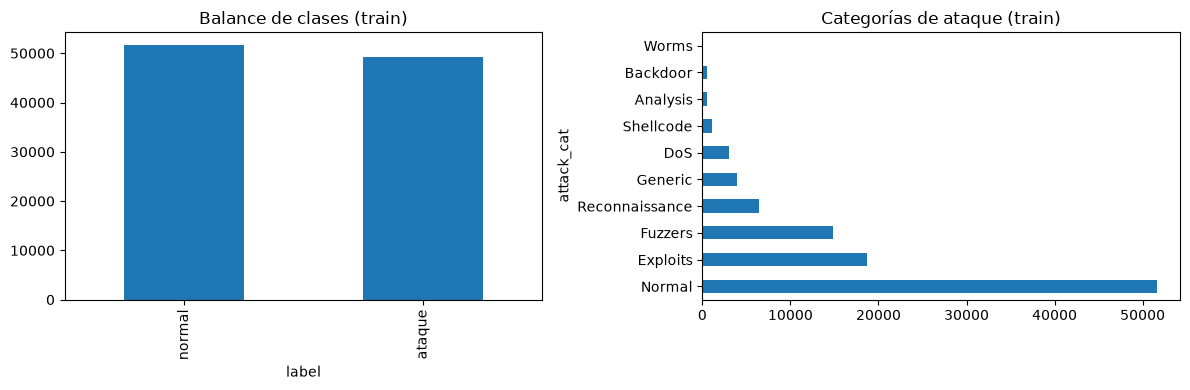

In [8]:
print(train["label"].value_counts().rename({0:"normal",1:"ataque"}))
print(train["label"].value_counts(normalize=True).round(3).rename({0:"normal",1:"ataque"}))
print("\nTest:", test["label"].value_counts(normalize=True).round(3).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
train["label"].map({0:"normal",1:"ataque"}).value_counts().plot.bar(ax=ax[0], title="Balance de clases (train)")
train["attack_cat"].value_counts().plot.barh(ax=ax[1], title="Categorías de ataque (train)")
plt.tight_layout(); plt.savefig("fig_balance_clases.png", dpi=150); plt.show()

## 4. Exploración de variables (solo train)

In [9]:
X_tr, y_tr, cat_tr = pp.separar_xy(train)
num_cols, cat_cols = pp.columnas_por_tipo(X_tr)
print(len(num_cols), "numéricas |", len(cat_cols), "categóricas")
X_tr[num_cols].describe().T[["mean","std","min","50%","max"]].round(2).head(15)

39 numéricas | 3 categóricas


,mean,std,min,50%,max
dur,1.27,4.950000e+00,0.0,0.37,6.000000e+01
spkts,31.78,1.790300e+02,1.0,10.00,9.616000e+03
dpkts,31.93,1.381100e+02,0.0,8.00,1.097400e+04
sbytes,14640.23,2.300994e+05,28.0,994.00,1.296523e+07
dbytes,25124.11,1.806643e+05,0.0,642.00,1.465555e+07
rate,28614.14,1.013933e+05,0.0,76.51,1.000000e+06
sttl,135.74,1.073000e+02,0.0,62.00,2.550000e+02
dttl,129.45,1.154000e+02,0.0,29.00,2.540000e+02
sload,42429408.09,2.108438e+08,0.0,53836.36,5.988000e+09
dload,1163920.98,3.101662e+06,0.0,9635.60,2.242273e+07


In [10]:
# Variables muy asimétricas: candidatas a log1p (se calcula con entrenamiento)
asim = X_tr[num_cols].skew().sort_values(ascending=False)
print(asim.head(12).round(1))
cols_log = pp.detectar_columnas_log(X_tr, num_cols, umbral_asimetria=2.0)
print("\nColumnas con log1p:", len(cols_log))

trans_depth          132.5
response_body_len     59.8
sbytes                34.4
sloss                 34.0
dloss                 33.0
dbytes                31.4
spkts                 31.1
dpkts                 29.3
dinpkt                29.0
djit                  26.1
sjit                  18.8
ct_flw_http_mthd      16.6
dtype: float64

Columnas con log1p: 30


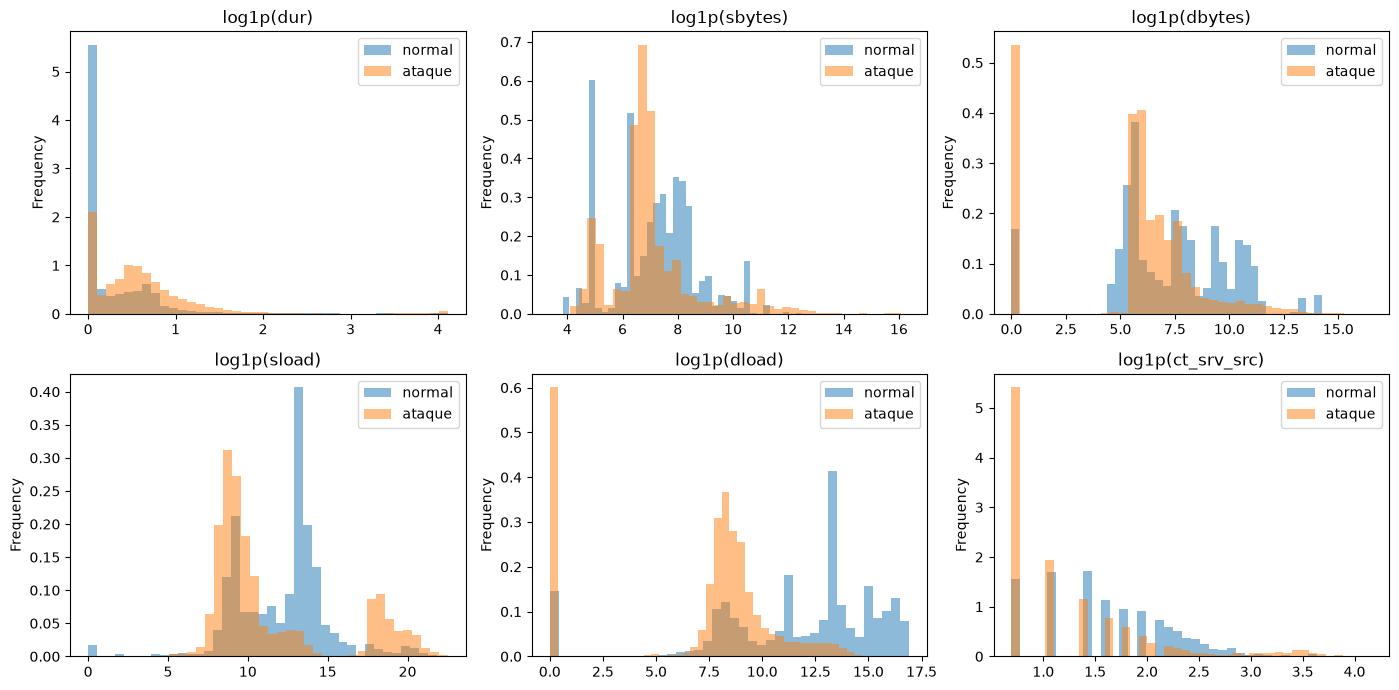

In [11]:
# Normal vs ataque en variables clave (escala log para verlas mejor)
clave = [c for c in ["dur","sbytes","dbytes","sload","dload","ct_srv_src"] if c in X_tr.columns]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), clave):
    for valor, nombre in [(0,"normal"),(1,"ataque")]:
        np.log1p(X_tr.loc[y_tr==valor, c].clip(lower=0)).plot.hist(ax=ax, bins=40, alpha=.5, label=nombre, density=True)
    ax.set_title(f"log1p({c})"); ax.legend()
plt.tight_layout(); plt.savefig("fig_normal_vs_ataque.png", dpi=150); plt.show()

sttl                0.590
dttl                0.557
ct_state_ttl        0.504
ackdat              0.389
tcprtt              0.381
dload              -0.353
synack              0.326
dmean              -0.208
ct_dst_sport_ltm    0.174
rate                0.174
dtype: float64

Pares con |corr| > 0.95 (posible redundancia): 8
is_ftp_login  ct_ftp_cmd    1.000
sbytes        sloss         0.997
dbytes        dloss         0.997
swin          dwin          0.984
dpkts         dloss         0.977
spkts         sloss         0.975
dpkts         dbytes        0.971
spkts         sbytes        0.967
dtype: float64


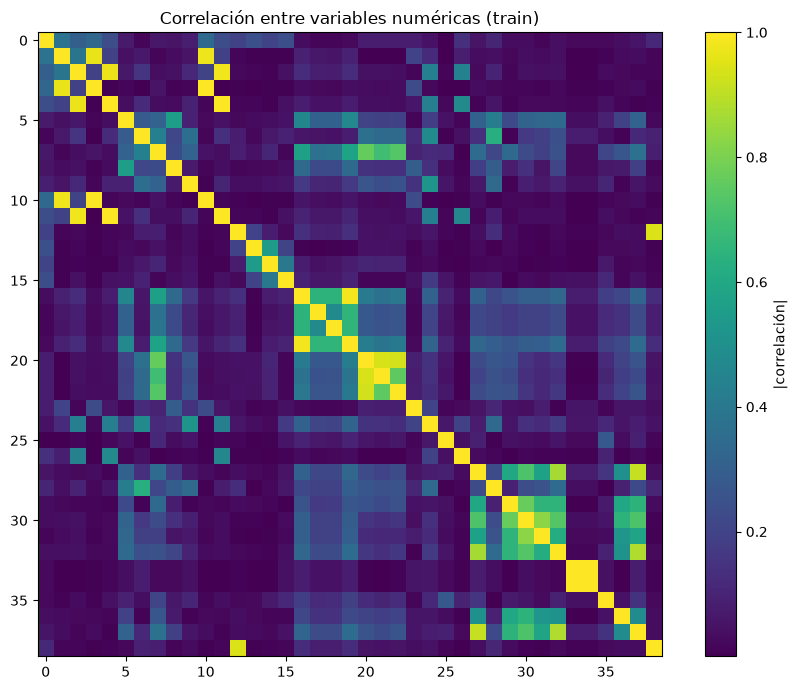

In [12]:
# Correlaciones: con la etiqueta y entre variables
corr_label = X_tr[num_cols].corrwith(y_tr).sort_values(key=abs, ascending=False)
print(corr_label.head(10).round(3))

corr = X_tr[num_cols].corr().abs()
sup = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
altas = sup.stack().loc[lambda s: s > 0.95].sort_values(ascending=False)
print("\nPares con |corr| > 0.95 (posible redundancia):", len(altas)); print(altas.head(10).round(3))

plt.figure(figsize=(9, 7)); plt.imshow(corr, cmap="viridis"); plt.colorbar(label="|correlación|")
plt.title("Correlación entre variables numéricas (train)"); plt.tight_layout()
plt.savefig("fig_correlaciones.png", dpi=150); plt.show()

## 5. Decisiones de limpieza, codificación, escalado y selección

| Decisión | Qué se hizo | Justificación |
|---|---|---|
| Columnas excluidas | `id`, `attack_cat` y `label` no entran como predictores. | `id` es solo un identificador. `attack_cat` revela la respuesta (fuga). `attack_cat` se conserva aparte para el análisis de errores. |
| Partición | Se mantiene la oficial: 175 341 para entrenamiento y 82 332 para prueba. Los nombres de los archivos vienen cruzados, así que se asignaron por tamaño. | Permite comparar con otros trabajos y evita particiones arbitrarias. |
| Faltantes | No hay (0 en ambas particiones). Se mantiene una imputación (mediana y constante) dentro del Pipeline. | Es una medida de seguridad para registros nuevos en el prototipo. |
| Duplicados | Se eliminan en entrenamiento (175 341 → 101 269, 42 %). En prueba se conservan (32 %). | Si un mismo registro cae en pliegues distintos de la validación cruzada, las métricas salen infladas. La prueba es la partición oficial y se deja intacta. |
| Etiquetas en conflicto | Se detectaron 229 duplicados con etiqueta distinta. | Es ruido de etiquetas; se reporta como limitación. |
| Solapamiento | 10,4 % de los registros de prueba son idénticos a alguno de entrenamiento. | Puede inflar ligeramente las métricas en prueba; se declara. |
| Categóricas | One-hot en `proto` (133 categorías), `service` (13) y `state` (9). Las categorías raras o nuevas se agrupan. | Los modelos necesitan números. Esto evita cientos de columnas casi vacías y maneja protocolos que solo aparecen en prueba. `-` en `service` (57,9 %) se trata como una categoría más. |
| Asimetría | `log1p` en 30 de las 39 variables numéricas. | Hay asimetrías extremas (`trans_depth` 133, `response_body_len` 60, `sbytes` 35). Esto perjudica a KNN, SVM y MLP. |
| Escalado | `StandardScaler` ajustado solo con entrenamiento. | KNN, SVM y MLP lo requieren. Random Forest no lo necesita, pero no se perjudica. |
| Selección de variables | Se excluye solo `ct_ftp_cmd`; se conservan las demás. | `ct_ftp_cmd` es idéntica a `is_ftp_login` (correlación 1,000). Los otros 7 pares redundantes (por ejemplo, `sbytes`–`sloss`, `dbytes`–`dloss`) no se quitan para no perder información. Random Forest no se ve afectado por ellos. |
| Submuestra | 25 000 registros estratificados por `attack_cat`, proporción de ataques 48,8 %. | Mantiene la proporción de cada tipo de ataque y hace que SVM y KNN corran en minutos. |

In [17]:
# Comprobar relación entre las dos variables
print("¿Son idénticas las columnas?")
print(
    train["ct_ftp_cmd"].equals(train["is_ftp_login"])
)

print("\nCorrelación:")
print(
    train[["ct_ftp_cmd", "is_ftp_login"]].corr()
)

print("\nValores distintos de cada columna:")
print("ct_ftp_cmd:", sorted(train["ct_ftp_cmd"].dropna().unique()))
print("is_ftp_login:", sorted(train["is_ftp_login"].dropna().unique()))

¿Son idénticas las columnas?
True

Correlación:
              ct_ftp_cmd  is_ftp_login
ct_ftp_cmd           1.0           1.0
is_ftp_login         1.0           1.0

Valores distintos de cada columna:
ct_ftp_cmd: [np.int64(0), np.int64(1), np.int64(2), np.int64(4)]
is_ftp_login: [np.int64(0), np.int64(1), np.int64(2), np.int64(4)]


In [19]:
for nombre, datos in [("train", train), ("test", test)]:
    print(
        f"{nombre}:",
        datos["ct_ftp_cmd"].equals(datos["is_ftp_login"])
    )

train: True
test: False


In [20]:
# Comparación de las columnas en entrenamiento y prueba

for nombre, datos in [("train", train), ("test", test)]:
    iguales = datos["ct_ftp_cmd"].eq(datos["is_ftp_login"])

    print(f"\n{nombre.upper()}")
    print("Registros:", len(datos))
    print("Valores iguales:", int(iguales.sum()))
    print("Valores diferentes:", int((~iguales).sum()))
    print("Porcentaje diferente:", round((~iguales).mean() * 100, 4), "%")


TRAIN
Registros: 100811
Valores iguales: 100811
Valores diferentes: 0
Porcentaje diferente: 0.0 %

TEST
Registros: 82332
Valores iguales: 82324
Valores diferentes: 8
Porcentaje diferente: 0.0097 %


## 6. Pipeline de preprocesamiento (ajustado solo con train) y submuestra

In [13]:
print("Entrenamiento después de limpiar:", train.shape)
print("Duplicados restantes:", train.duplicated(
    subset=feat
).sum())
# Submuestra estratificada del entrenamiento (para que SVM y KNN corran en minutos)
N_SUBMUESTRA = 25000
train_sub = pp.submuestra_estratificada(train, N_SUBMUESTRA, col_estrato="attack_cat", semilla=SEED)
print("Submuestra:", train_sub.shape)
print("Proporción de ataques -> completo:", train["label"].mean().round(3), "| submuestra:", train_sub["label"].mean().round(3))

Entrenamiento después de limpiar: (100811, 45)
Duplicados restantes: 0
Submuestra: (25000, 45)
Proporción de ataques -> completo: 0.488 | submuestra: 0.488


In [14]:
X_sub, y_sub, cat_sub = pp.separar_xy(train_sub)
X_te,  y_te,  cat_te  = pp.separar_xy(test)

# Columnas log y tipos decididos con la submuestra de entrenamiento (nunca con test)
num_cols, cat_cols = pp.columnas_por_tipo(X_sub)
cols_log = pp.detectar_columnas_log(X_sub, num_cols)
preprocesador = pp.construir_preprocesador(num_cols, cat_cols, cols_log)

Xt_sub = preprocesador.fit_transform(X_sub)      # fit SOLO con entrenamiento
Xt_te  = preprocesador.transform(X_te)           # test: solo transform
print("Matriz train:", Xt_sub.shape, "| matriz test:", Xt_te.shape)
print("NaN tras transformar:", int(np.isnan(Xt_sub).sum()), int(np.isnan(Xt_te).sum()))

Matriz train: (25000, 59) | matriz test: (82332, 59)
NaN tras transformar: 0 0


## 7. Chequeos anti-fuga (para que la Persona B los verifique)

In [15]:
nuevas = pp.categorias_nuevas_en_prueba(X_sub, X_te, cat_cols)
print("Categorías en test que no existen en train:", {k: v for k, v in nuevas.items() if v})

# El escalador debe tener la media de TRAIN, no la de test
bloque = "num" if "num" in preprocesador.named_transformers_ else "num_log"
esc = preprocesador.named_transformers_[bloque].named_steps["esc"]
col0 = [t for t in preprocesador.transformers_ if t[0] == bloque][0][2][0]
print(f"Media de '{col0}' -> escalador: {esc.mean_[0]:.4f} | train (tras imputar): {X_sub[col0].mean():.4f} | test: {X_te[col0].mean():.4f}")
print("(si hay log1p, la media del escalador es la de log1p(train), por eso no coincide exactamente; lo importante es que no sea la de test)")
assert "attack_cat" not in X_sub.columns and "id" not in X_sub.columns and "label" not in X_sub.columns
print("OK: sin attack_cat, id ni label entre los predictores.")

Categorías en test que no existen en train: {'proto': {'aris', 'idpr-cmtp', 'kryptolan', 'iso-ip', 'iatp', 'egp', 'smp', 'ipv6-no', 'ipv6-opts', 'xns-idp', '3pc', 'trunk-1', 'pup', 'ipv6-route', 'argus', 'isis', 'iso-tp4', 'skip', 'snp', 'prm'}, 'state': {'ACC', 'CLO'}}
Media de 'sttl' -> escalador: 136.2169 | train (tras imputar): 136.2169 | test: 180.9677
(si hay log1p, la media del escalador es la de log1p(train), por eso no coincide exactamente; lo importante es que no sea la de test)
OK: sin attack_cat, id ni label entre los predictores.


## 8. Guardar datos particionados para el equipo

In [16]:
DIR_SALIDA = "../data/processed"
os.makedirs(DIR_SALIDA, exist_ok=True)
train_sub.to_csv(f"{DIR_SALIDA}/train_submuestra.csv", index=False)
test.to_csv(f"{DIR_SALIDA}/test_completo.csv", index=False)
print("Guardado en", DIR_SALIDA)

Guardado en ../data/processed


## 9. Notas para el informe
- Tamaño, faltantes, duplicados y balance de clases: *(anota las cifras reales de arriba)*.
- Sesgos: dataset simulado en laboratorio (2015), desbalance entre categorías de ataque, vigencia de los ataques.
- Semilla fija 42; versiones de software y hardware impresas en la sección 0.